# BurnInWatch — Canonical Aging Dataset Construction v1

## Current findings

From the previous notebook:

- SMU data contains 120 files = 2 device families × 20 parts × 3 test types.
- Each SMU CSV contains two numerical columns and no header.
- The device aging files contain `measurement.steadyState` records.
- Each steady-state record contains:
  - `date`
  - `timeEpoch`
  - `timeDomain`
- `timeDomain` contains:
  - `supplyVoltage`
  - `node1Voltage`
  - `node2Voltage`
  - `collectorEmitterCurrent`
  - `heatSinkTemperature`
  - `packageTemperature`
  - `internalTemperature`
  - `ambientTemperature`
- The first steady-state record contains NaNs for these engineering values, so **we must not assume all records are valid measurements**.
- The large DC experiment is a high-frequency switching time series with a duration of about 4.19 hours.

This notebook now answers the critical question:

> How many valid engineering measurements do we actually have across each aging file, and can we construct a trustworthy canonical aging CSV?

We still do NOT train an anomaly detector here.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

DATA_ROOT = Path("dataset/Data").resolve()
OUT_DIR = Path("processed")
OUT_DIR.mkdir(exist_ok=True)

print("Dataset:", DATA_ROOT)

Dataset: C:\Users\Abhishek Kuma\Desktop\BurnInWatch\dataset\Data


## 1. Enumerate aging files and identify device/file role

The filenames are part of the metadata. We preserve the exact source filename and create a simple descriptive `file_role` based only on the filename text.

This is metadata—not a target label.

In [2]:
# ============================================================
# 1. AGING FILE METADATA
# ============================================================

aging_files = sorted(
    p for p in DATA_ROOT.rglob("*.mat")
    if "Aging Data" in str(p)
)

def get_device_id(path):
    for part in path.relative_to(DATA_ROOT).parts:
        if part.lower().startswith("device "):
            return part.replace(" ", "_")
    return "unknown"

def get_file_role(path):
    name = path.stem.lower()
    if "check" in name:
        return "check"
    if name.endswith("b") or "b " in name:
        return "b"
    return "main"

aging_file_meta = pd.DataFrame([
    {
        "device_id": get_device_id(p),
        "file_name": p.name,
        "file_role_inferred": get_file_role(p),
        "relative_path": str(p.relative_to(DATA_ROOT))
    }
    for p in aging_files
])

display(aging_file_meta)
aging_file_meta.to_csv(
    OUT_DIR / "aging_file_metadata.csv",
    index=False
)

,device_id,file_name,file_role_inferred,relative_path
0,Device_2,Device2 1.mat,main,Thermal Overstress Aging with Square Signal at...
1,Device_2,Device2b 1.mat,b,Thermal Overstress Aging with Square Signal at...
2,Device_2,Device2check 1.mat,check,Thermal Overstress Aging with Square Signal at...
3,Device_3,Device3 1.mat,main,Thermal Overstress Aging with Square Signal at...
4,Device_3,Device3b 1.mat,b,Thermal Overstress Aging with Square Signal at...
5,Device_3,Device3check 1.mat,check,Thermal Overstress Aging with Square Signal at...
6,Device_4,Device4 1.mat,main,Thermal Overstress Aging with Square Signal at...
7,Device_4,Device4b 1.mat,b,Thermal Overstress Aging with Square Signal at...
8,Device_5,Device5 1.mat,main,Thermal Overstress Aging with Square Signal at...
9,Device_5,Device5check 1.mat,check,Thermal Overstress Aging with Square Signal at...


## 2. Measure validity: non-NaN counts for every engineering field

Instead of looking only at `steadyState[0]`, we scan every record.

For each field we calculate:

- number of records
- valid numeric records
- NaN records
- minimum
- maximum
- mean
- standard deviation

This tells us whether the engineering data is actually populated.

In [3]:
# ============================================================
# 2. FULL STEADY-STATE QUALITY SCAN
# ============================================================

ENGINEERING_FIELDS = [
    "supplyVoltage",
    "node1Voltage",
    "node2Voltage",
    "collectorEmitterCurrent",
    "heatSinkTemperature",
    "packageTemperature",
    "internalTemperature",
    "ambientTemperature",
]

quality_rows = []

for path in aging_files:
    try:
        data = loadmat(path, squeeze_me=True, struct_as_record=False)
        measurement = data["measurement"]
        steady = getattr(measurement, "steadyState", [])

        total_records = len(steady)

        for field in ENGINEERING_FIELDS:
            values = []

            for record in steady:
                td = getattr(record, "timeDomain", None)
                value = getattr(td, field, np.nan) if td is not None else np.nan

                try:
                    values.append(float(value))
                except Exception:
                    values.append(np.nan)

            values = np.asarray(values, dtype=float)
            valid = values[np.isfinite(values)]

            quality_rows.append({
                "device_id": get_device_id(path),
                "file_name": path.name,
                "file_role": get_file_role(path),
                "field": field,
                "total_records": total_records,
                "valid_records": len(valid),
                "nan_records": total_records - len(valid),
                "valid_fraction": len(valid) / total_records if total_records else np.nan,
                "min": np.min(valid) if len(valid) else np.nan,
                "max": np.max(valid) if len(valid) else np.nan,
                "mean": np.mean(valid) if len(valid) else np.nan,
                "std": np.std(valid) if len(valid) else np.nan,
            })

    except Exception as e:
        print("FAILED:", path.relative_to(DATA_ROOT), repr(e))

quality_df = pd.DataFrame(quality_rows)

display(
    quality_df.sort_values(
        ["device_id", "file_name", "field"]
    )
)

quality_df.to_csv(
    OUT_DIR / "aging_signal_quality.csv",
    index=False
)

,device_id,file_name,file_role,field,total_records,valid_records,nan_records,valid_fraction,min,max,mean,std
7,Device_2,Device2 1.mat,main,ambientTemperature,10978,0,10978,0.000000,NaN,NaN,NaN,NaN
3,Device_2,Device2 1.mat,main,collectorEmitterCurrent,10978,10977,1,0.999909,-0.220997,0.450467,0.107798,0.036705
4,Device_2,Device2 1.mat,main,heatSinkTemperature,10978,10977,1,0.999909,718.787773,719.129957,718.953336,0.097168
6,Device_2,Device2 1.mat,main,internalTemperature,10978,10977,1,0.999909,-2260.806388,-2253.824736,-2257.051709,1.867826
1,Device_2,Device2 1.mat,main,node1Voltage,10978,10977,1,0.999909,2.437638,5.442653,4.722203,0.937872
...,...,...,...,...,...,...,...,...,...,...,...,...
78,Device_5,Device5check 1.mat,check,internalTemperature,162,161,1,0.993827,-2262.029387,-2261.695723,-2261.826970,0.075288
73,Device_5,Device5check 1.mat,check,node1Voltage,162,161,1,0.993827,2.459744,2.465271,2.461598,0.001034
74,Device_5,Device5check 1.mat,check,node2Voltage,162,161,1,0.993827,2.443267,2.458483,2.454161,0.002184
77,Device_5,Device5check 1.mat,check,packageTemperature,162,161,1,0.993827,38.110246,39.308257,38.771394,0.234195


In [4]:
# ============================================================
# 2B. VALIDITY HEATMAP TABLE
# ============================================================

validity_table = quality_df.pivot_table(
    index=["device_id", "file_name"],
    columns="field",
    values="valid_fraction"
)

display(validity_table)

print("\nAverage valid fraction by field:")
display(
    quality_df.groupby("field")["valid_fraction"]
    .mean()
    .sort_values()
    .to_frame()
)

field                          ambientTemperature  collectorEmitterCurrent  heatSinkTemperature  internalTemperature  node1Voltage  node2Voltage  packageTemperature  \
device_id file_name                                                                                                                                                    
Device_2  Device2  1.mat                      0.0                 0.999909             0.999909             0.999909      0.999909      0.999909            0.999909   
          Device2b  1.mat                     0.0                 0.999845             0.999845             0.999845      0.999845      0.999845            0.999845   
          Device2check  1.mat                 0.0                 1.000000             1.000000             1.000000      1.000000      1.000000            1.000000   
Device_3  Device3  1.mat                      0.0                 0.999898             0.999898             0.999898      0.999898      0.999898            0.999898   
          Device3b  1.mat                     0.0                 1.000000             1.000000             1.000000      1.000000      1.000000            1.000000   
          Device3check  1.mat                 0.0                 0.991150             0.991150             0.991150      0.991150      0.991150            0.991150   
Device_4  Device4  1.mat                      0.0                 0.999907             0.999907             0.999907      0.999907      0.999907            0.999907   
          Device4b  1.mat                     0.0                 0.999932             0.999932             0.999932      0.999932      0.999932            0.999932   
Device_5  Device5  1.mat                      0.0                 0.999905             0.999905             0.999905      0.999905      0.999905            0.999905   
          Device5check  1.mat                 0.0                 0.993827             0.993827             0.993827      0.993827      0.993827            0.993827   

field                          supplyVoltage  
device_id file_name                           
Device_2  Device2  1.mat            0.999909  
          Device2b  1.mat           0.999845  
          Device2check  1.mat       1.000000  
Device_3  Device3  1.mat            0.999898  
          Device3b  1.mat           1.000000  
          Device3check  1.mat       0.991150  
Device_4  Device4  1.mat            0.999907  
          Device4b  1.mat           0.999932  
Device_5  Device5  1.mat            0.999905  
          Device5check  1.mat       0.993827


Average valid fraction by field:


,valid_fraction
field,
ambientTemperature,0.000000
collectorEmitterCurrent,0.998437
heatSinkTemperature,0.998437
internalTemperature,0.998437
node1Voltage,0.998437
node2Voltage,0.998437
packageTemperature,0.998437
supplyVoltage,0.998437


## 3. Extract all valid steady-state engineering measurements

We now build the canonical table.

One row = **one steady-state event**.

Important fields:

- `device_id`
- `file_name`
- `file_role`
- `event_index`
- `date`
- `timeEpoch`
- engineering measurements from `timeDomain`

Invalid/all-NaN engineering rows are retained initially with a `measurement_valid` flag, then we create a clean version by removing rows where all engineering signals are missing.

In [5]:
# ============================================================
# 3. EXTRACT CANONICAL STEADY-STATE TABLE
# ============================================================

rows = []

for path in aging_files:
    data = loadmat(path, squeeze_me=True, struct_as_record=False)
    measurement = data["measurement"]
    steady = getattr(measurement, "steadyState", [])

    device_id = get_device_id(path)
    file_role = get_file_role(path)

    for event_index, record in enumerate(steady):
        td = getattr(record, "timeDomain", None)

        row = {
            "device_id": device_id,
            "file_name": path.name,
            "file_role": file_role,
            "event_index": event_index,
            "date": getattr(record, "date", None),
            "timeEpoch": getattr(record, "timeEpoch", np.nan),
        }

        for field in ENGINEERING_FIELDS:
            value = getattr(td, field, np.nan) if td is not None else np.nan

            try:
                value = float(value)
            except Exception:
                value = np.nan

            row[field] = value

        engineering_values = np.array(
            [row[f] for f in ENGINEERING_FIELDS],
            dtype=float
        )

        row["measurement_valid"] = bool(
            np.isfinite(engineering_values).any()
        )

        rows.append(row)

aging_raw = pd.DataFrame(rows)

print("Raw steady-state rows:", len(aging_raw))
print("Columns:", list(aging_raw.columns))

display(aging_raw.head(10))

Raw steady-state rows: 68769
Columns: ['device_id', 'file_name', 'file_role', 'event_index', 'date', 'timeEpoch', 'supplyVoltage', 'node1Voltage', 'node2Voltage', 'collectorEmitterCurrent', 'heatSinkTemperature', 'packageTemperature', 'internalTemperature', 'ambientTemperature', 'measurement_valid']


,device_id,file_name,file_role,event_index,date,timeEpoch,supplyVoltage,node1Voltage,node2Voltage,collectorEmitterCurrent,heatSinkTemperature,packageTemperature,internalTemperature,ambientTemperature,measurement_valid
0,Device_2,Device2 1.mat,main,0,12/31/1903 4:00:00 PM,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,Device_2,Device2 1.mat,main,1,12/24/2008 9:59:48 AM,3.312986e+09,2.447730,2.443165,1.910721,0.157385,718.797002,30.404121,-2254.045786,NaN,True
2,Device_2,Device2 1.mat,main,2,12/24/2008 9:59:48 AM,3.312986e+09,2.443545,2.450073,1.737816,0.083021,718.801617,30.145092,-2254.266875,NaN,True
3,Device_2,Device2 1.mat,main,3,12/24/2008 9:59:48 AM,3.312986e+09,2.461683,2.456981,2.013080,0.087395,718.801617,30.080334,-2254.266875,NaN,True
4,Device_2,Device2 1.mat,main,4,12/24/2008 9:59:48 AM,3.312986e+09,2.461683,2.443165,2.043511,0.174882,718.797002,30.209849,-2254.045786,NaN,True
5,Device_2,Device2 1.mat,main,5,12/24/2008 9:59:48 AM,3.312986e+09,2.456102,2.452836,1.824960,0.085208,718.801617,30.371743,-2254.156325,NaN,True
6,Device_2,Device2 1.mat,main,6,12/24/2008 9:59:49 AM,3.312986e+09,2.458892,2.456981,1.932852,0.087395,718.801617,30.177471,-2254.266875,NaN,True
7,Device_2,Device2 1.mat,main,7,12/24/2008 9:59:49 AM,3.312986e+09,2.460287,2.455599,1.919020,0.087395,718.797002,30.566015,-2254.045786,NaN,True
8,Device_2,Device2 1.mat,main,8,12/24/2008 9:59:49 AM,3.312986e+09,2.461683,2.459744,2.008930,0.085208,718.801617,30.776476,-2254.156325,NaN,True
9,Device_2,Device2 1.mat,main,9,12/24/2008 9:59:49 AM,3.312986e+09,2.443545,2.441783,1.769630,0.177070,718.810847,30.485068,-2254.156325,NaN,True


In [6]:
# ============================================================
# 3B. CREATE CLEAN CANONICAL AGING CSV
# ============================================================

engineering_present = np.isfinite(
    aging_raw[ENGINEERING_FIELDS].to_numpy(dtype=float)
).any(axis=1)

aging_clean = aging_raw.loc[engineering_present].copy()

# Sort by device/file/event, preserving recorded sequence.
aging_clean = aging_clean.sort_values(
    ["device_id", "file_name", "event_index"]
).reset_index(drop=True)

print("Rows before removing all-missing measurements:", len(aging_raw))
print("Rows after:", len(aging_clean))
print("Rows removed:", len(aging_raw) - len(aging_clean))

display(aging_clean.head())
display(aging_clean[ENGINEERING_FIELDS].describe().T)

aging_clean.to_csv(
    OUT_DIR / "burninwatch_aging_canonical_v1.csv",
    index=False
)

print("Saved:", OUT_DIR / "burninwatch_aging_canonical_v1.csv")

Rows before removing all-missing measurements: 68769
Rows after: 68761
Rows removed: 8


,device_id,file_name,file_role,event_index,date,timeEpoch,supplyVoltage,node1Voltage,node2Voltage,collectorEmitterCurrent,heatSinkTemperature,packageTemperature,internalTemperature,ambientTemperature,measurement_valid
0,Device_2,Device2 1.mat,main,1,12/24/2008 9:59:48 AM,3.312986e+09,2.447730,2.443165,1.910721,0.157385,718.797002,30.404121,-2254.045786,NaN,True
1,Device_2,Device2 1.mat,main,2,12/24/2008 9:59:48 AM,3.312986e+09,2.443545,2.450073,1.737816,0.083021,718.801617,30.145092,-2254.266875,NaN,True
2,Device_2,Device2 1.mat,main,3,12/24/2008 9:59:48 AM,3.312986e+09,2.461683,2.456981,2.013080,0.087395,718.801617,30.080334,-2254.266875,NaN,True
3,Device_2,Device2 1.mat,main,4,12/24/2008 9:59:48 AM,3.312986e+09,2.461683,2.443165,2.043511,0.174882,718.797002,30.209849,-2254.045786,NaN,True
4,Device_2,Device2 1.mat,main,5,12/24/2008 9:59:48 AM,3.312986e+09,2.456102,2.452836,1.824960,0.085208,718.801617,30.371743,-2254.156325,NaN,True


,count,mean,std,min,25%,50%,75%,max
supplyVoltage,68761.0,4.707065,1.089938,2.114267,3.944827,4.936846,5.427972,5.959560
node1Voltage,68761.0,4.704696,1.089821,2.111577,3.942218,4.935600,5.426074,5.957996
node2Voltage,68761.0,4.373966,1.104186,1.151323,3.594121,4.912348,5.119834,5.934561
collectorEmitterCurrent,68761.0,0.106224,0.038150,-0.518453,0.085208,0.091770,0.133326,0.605757
heatSinkTemperature,68761.0,719.129660,0.101922,718.787773,719.078999,719.171676,719.194862,719.301610
packageTemperature,68761.0,220.001322,63.963280,27.846206,175.703674,254.416800,269.116877,297.723799
internalTemperature,68761.0,-2260.580357,1.977514,-2263.030915,-2261.806934,-2261.473330,-2259.584582,-2253.824736
ambientTemperature,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saved: processed\burninwatch_aging_canonical_v1.csv


In [7]:
# ============================================================
# 4. CHECK TIME PROGRESSION PER DEVICE FILE
# ============================================================

time_rows = []

for (device_id, file_name), group in aging_clean.groupby(
    ["device_id", "file_name"]
):
    t = pd.to_numeric(group["timeEpoch"], errors="coerce")
    dt = t.diff().dropna()

    time_rows.append({
        "device_id": device_id,
        "file_name": file_name,
        "records": len(group),
        "time_min": t.min(),
        "time_max": t.max(),
        "duration": t.max() - t.min(),
        "median_dt": dt.median() if len(dt) else np.nan,
        "mean_dt": dt.mean() if len(dt) else np.nan,
        "nonpositive_dt": int((dt <= 0).sum()),
        "missing_time": int(t.isna().sum()),
    })

aging_time_summary = pd.DataFrame(time_rows)

display(aging_time_summary)
aging_time_summary.to_csv(
    OUT_DIR / "aging_time_summary.csv",
    index=False
)

,device_id,file_name,records,time_min,time_max,duration,median_dt,mean_dt,nonpositive_dt,missing_time
0,Device_2,Device2 1.mat,10977,3.312986e+09,3.312989e+09,2501.324,0.2,0.227890,0,0
1,Device_2,Device2b 1.mat,6434,3.312989e+09,3.312991e+09,1491.484,0.2,0.231849,0,0
2,Device_2,Device2check 1.mat,116,3.313009e+09,3.313009e+09,30.621,0.2,0.266270,0,0
3,Device_3,Device3 1.mat,9836,3.313005e+09,3.313007e+09,2267.172,0.2,0.230521,0,0
4,Device_3,Device3b 1.mat,5238,3.313007e+09,3.313008e+09,1198.802,0.2,0.228910,0,0
5,Device_3,Device3check 1.mat,112,3.313008e+09,3.313008e+09,25.191,0.2,0.226946,0,0
6,Device_4,Device4 1.mat,10770,3.313009e+09,3.313011e+09,2460.353,0.2,0.228466,0,0
7,Device_4,Device4b 1.mat,14607,3.313012e+09,3.313016e+09,3350.811,0.2,0.229413,0,0
8,Device_5,Device5 1.mat,10510,3.312994e+09,3.312997e+09,2386.039,0.2,0.227047,0,0
9,Device_5,Device5check 1.mat,161,3.313009e+09,3.313009e+09,37.871,0.2,0.236694,0,0


## 5. Trend plots for the canonical aging measurements

These plots are deliberately grouped by device/file.

We are looking for:
- stable vs drifting behavior
- sudden excursions
- temperature changes
- current changes
- whether different files represent different stages/experiments

We do NOT call anything an anomaly yet.

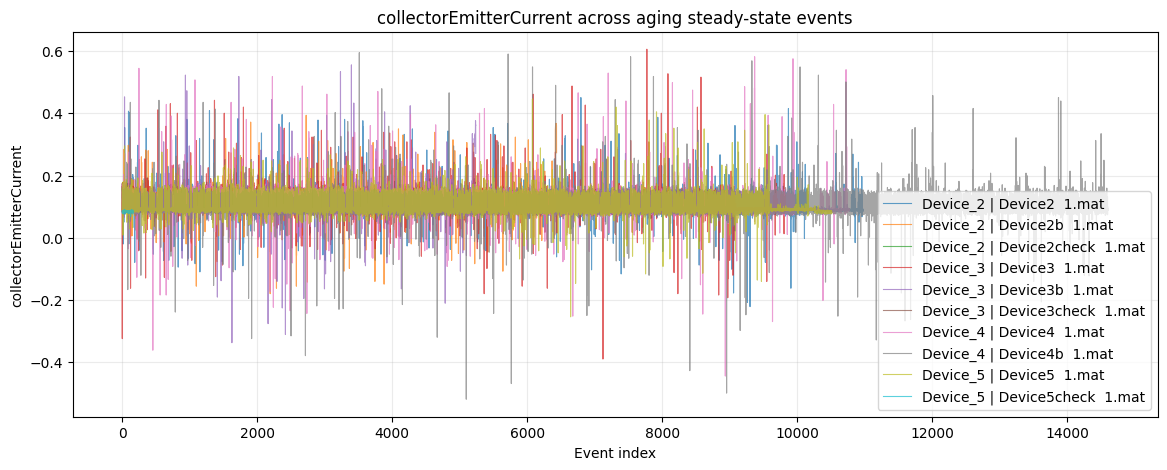

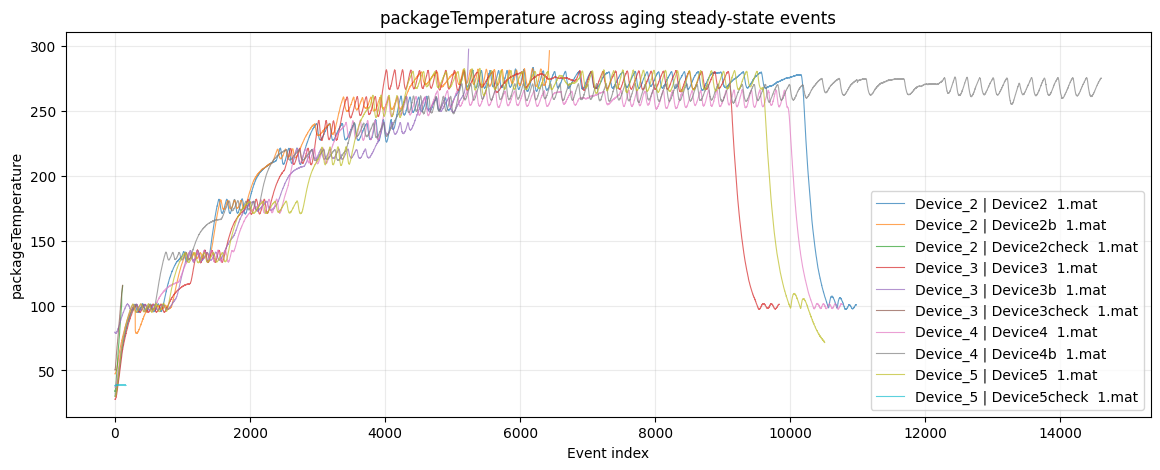

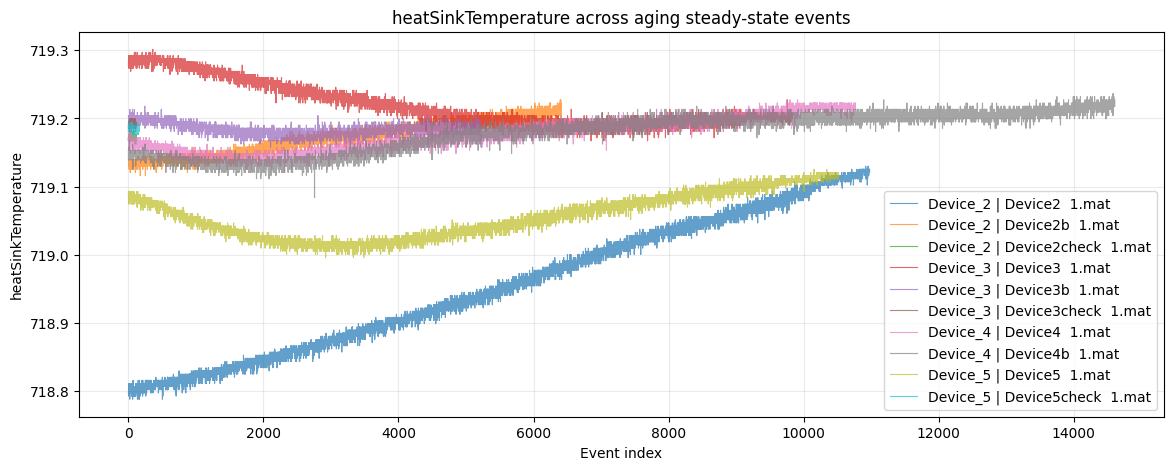

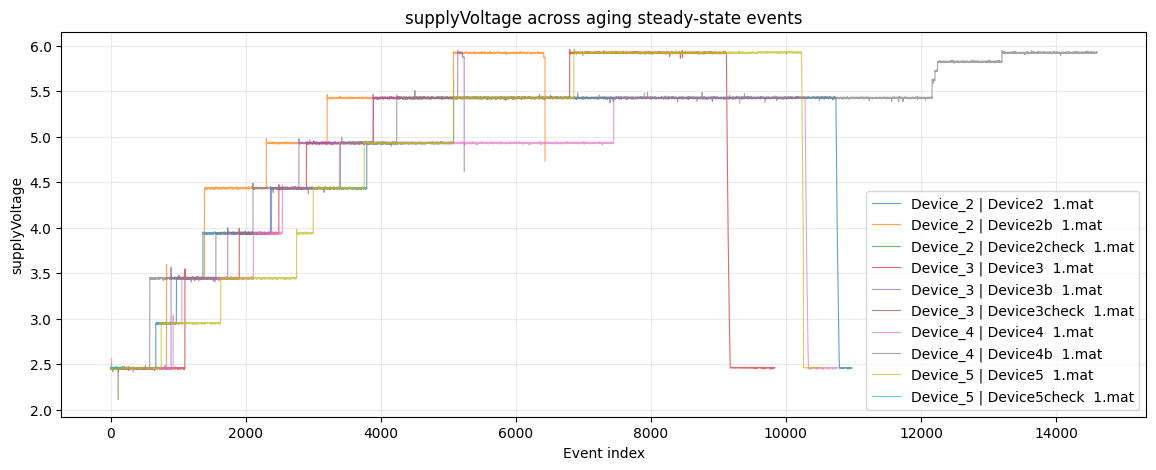

In [8]:
# ============================================================
# 5. PLOT ENGINEERING SIGNALS
# ============================================================

signals_to_plot = [
    "collectorEmitterCurrent",
    "packageTemperature",
    "heatSinkTemperature",
    "supplyVoltage",
]

for signal in signals_to_plot:
    fig, ax = plt.subplots(figsize=(14, 5))

    for (device_id, file_name), group in aging_clean.groupby(
        ["device_id", "file_name"]
    ):
        ax.plot(
            group["event_index"],
            group[signal],
            linewidth=0.8,
            alpha=0.7,
            label=f"{device_id} | {file_name}"
        )

    ax.set_title(f"{signal} across aging steady-state events")
    ax.set_xlabel("Event index")
    ax.set_ylabel(signal)
    ax.grid(alpha=0.25)

    # Avoid unreadable legends if there are many files.
    if aging_clean[["device_id", "file_name"]].drop_duplicates().shape[0] <= 10:
        ax.legend()

    plt.show()

# STOP POINT

Run this notebook and send the outputs for:

1. **`aging_signal_quality`**
2. **validity table**
3. **canonical dataset shape + first rows**
4. **aging time summary**
5. **the four trend plots**

The next decision will be based on these actual results:

- whether `steadyState` is our main dataset
- whether we should use `main`, `b`, and `check` files together
- whether the flat DC experiment should be a separate experiment/validation source
- how the 120 new-device SMU measurements should enter the baseline
- how to create time-window features without leakage

Only after that will we make the first serious feature-engineering notebook.